# Programming Sheet 3: Principal Component Analysis

We compute the principal components of face images in two ways, with the singular value decomposition and with the power iteration, and use them to compress and reconstruct faces.

**Quiz.** Each exercise asks for one function, with the same name and arguments as in the ISIS quiz for this sheet, which also contains a few short multiple-choice questions. The quiz checks your functions on several inputs (also on a smaller version of the face data, 31 × 23 pixels) and explains with figures what they compute.


In [1]:
import numpy as np
import matplotlib
%matplotlib inline
from matplotlib import pyplot as plt
import sklearn.datasets
import utils

## Data: Faces

We take 2000 random images of the _Labeled Faces in the Wild_ dataset (LFW), 62 × 47 pixels in gray values, readily accessible from scikit-learn (the first call downloads about 200 MB and needs the package `pillow` to read the images). Every image is a point $\boldsymbol{x} \in \mathbb{R}^d$ with $d = 62 \cdot 47 = 2914$, one entry per pixel. As in the lecture, the data is stored row by row: `X` has shape (N, d), row $k$ is $\boldsymbol{x}_k^\top$.

Each image is standardized on its own: the mean of its gray values is subtracted, and the result is divided by their standard deviation. We keep the original gray values, between 0 and 1, in `X_raw` and come back to this step at the end of Exercise 1.


In [2]:
# Extract images (gray values between 0 and 1)
images = sklearn.datasets.fetch_lfw_people(resize=0.5)["images"]
order = np.random.mtrand.RandomState(1).permutation(len(images))
images = images[order[:2000]] * 1.0

# Save raw images
X_raw = images.reshape(len(images), -1)

# Apply standardization
mean = images.mean(axis=(1, 2), keepdims=True)  # one per image
std = images.std(axis=(1, 2), keepdims=True)
images = (images - mean) / std
X = images.reshape(len(images), -1)

N, d = X.shape
print(f"N = {N}, d = {d}")

N = 2000, d = 2914


Two helpers are given in `utils.py`, which is included in the zip archive: `utils.render(x, w, h)` shows the rows of `x` as images in a grid of `h` rows and `w` columns (gray is 0), and `utils.scatterplot(x, y)` draws a scatter plot. Here, the first 20 faces and the gray values of two neighboring pixels across all images:


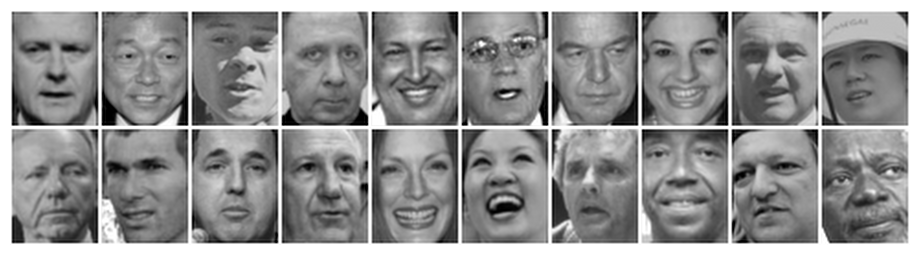

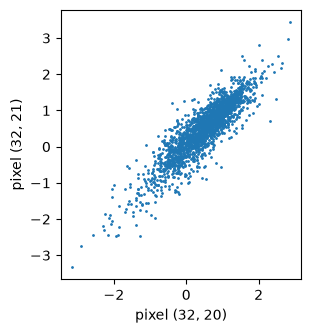

In [3]:
utils.render(X[:20], 10, 2, vmax=3)
utils.scatterplot(
    X[:, 32 * 47 + 20], X[:, 32 * 47 + 21], "pixel (32, 20)", "pixel (32, 21)"
)

Neighboring pixels are strongly correlated: the data does not fill all $d$ dimensions, but lies close to a much smaller subspace. PCA finds this subspace.

## Exercise 1: Principal Components via the SVD

With the mean $\boldsymbol{\mu} = \frac1N \sum_k \boldsymbol{x}_k$ and the centered data $\bar X = X - \boldsymbol{\mu}^\top$ (the mean subtracted from every row), the covariance matrix is

$$
\widehat\Sigma = \frac1N \sum_{k=1}^N (\boldsymbol{x}_k - \boldsymbol{\mu})(\boldsymbol{x}_k - \boldsymbol{\mu})^\top = \frac1N \bar X^\top \bar X \qquad (d \times d).
$$

The principal components are its eigenvectors $\boldsymbol{w}_1, \dots, \boldsymbol{w}_d$, with unit length, ordered by their eigenvalues $\lambda_1 \geq \dots \geq \lambda_d$; $\lambda_i$ is the variance of the data along $\boldsymbol{w}_i$. Instead of forming $\widehat\Sigma$, compute the singular value decomposition of the scaled centered data,

$$
\frac{1}{\sqrt N}\, \bar X = U S V^\top, \qquad \text{so that} \qquad \widehat\Sigma = V S^2 V^\top:
$$

the columns of $V$ are the principal components, and $\lambda_i = s_i^2$. `U, s, Vt = np.linalg.svd(A, full_matrices=False)` returns the singular values `s` in decreasing order and $V^\top$ as `Vt`, so the components are its rows. (The lecture stores the points as columns, a $d \times N$ matrix; there the components are in $U$. With points as rows, as here, they are in $V$.)

- **Implement `pca_svd(X, k)`**, which returns the pair `(W, lambdas)`: the first $k$ principal components as the columns of `W`, an array of shape (d, k), and the variances $\lambda_1, \dots, \lambda_k$ along them, an array of shape (k,). A component and its negative are the same direction: both signs are correct.


In [ ]:
def pca_svd(X: np.ndarray, k: int) -> tuple[np.ndarray, np.ndarray]:
    """
    Calculate the first k principal components using SVD.

    Args:
        X (np.ndarray): Data matrix of shape (N, d).
        k (int): Number of principal components to return.

    Returns:
        W (np.ndarray): Principal components of shape (d, k).
        lambdas (np.ndarray): Corresponding eigenvalues of shape (k,).
    """
    # Center data
    mu = np.mean(X, axis=0)  # axis=0 averages across rows -> one mean for each column
    print("mu shape: ", mu.shape)
    X_centered = X - mu  # np broadcasts mu across all rows

    # Scale data
    A = X_centered / np.sqrt(N)

    # Compute SVD
    U, s, Vt = np.linalg.svd(A, full_matrices=False)

    # Extract pcs as cols (Vt stores principal components as rows)
    W = Vt[:k].T  # stop index is not included
    print("W shape: ", W.shape)

    # Extract eigenvalues (s stores singular values in descending order)
    lambdas = s[:k] ** 2
    print("lambdas shape: ", lambdas.shape)

    return W, lambdas

We compute the first 100 components of the faces, plot the faces along the first two and show the first 30 components as images, the _eigenfaces_.


mu shape:  (2914,)
W shape:  (2914, 100)
lambdas shape:  (100,)
the first 100 of 2914 components hold 86% of the variance


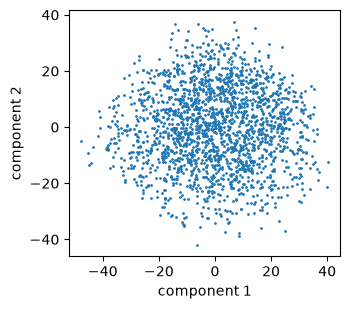

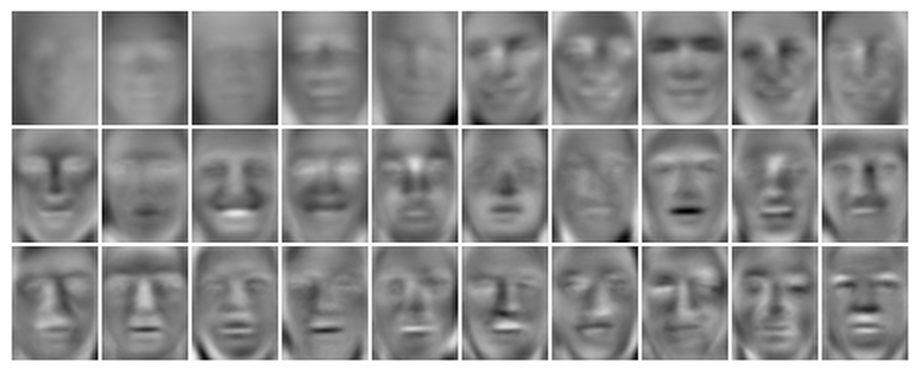

In [5]:
W, lambdas = pca_svd(X, 100)
mu = X.mean(axis=0)
total = np.sum((X - mu) ** 2) / N  # sum of all d variances
print(
    f"the first 100 of {d} components hold "
    f"{np.sum(lambdas) / total:.0%} of the variance"
)

H = (X - mu) @ W[:, :2]  # coordinates along components 1 and 2
utils.scatterplot(H[:, 0], H[:, 1], "component 1", "component 2")
utils.render(W[:, :30].T, 10, 3)

Along the first two components, the faces vary much more than along the two single pixels above. The first components are smooth images that capture lighting and the overall shape of a face; later ones capture finer and finer details.

**Question.** Mathematically, the eigenvectors of $\widehat\Sigma$ (for example from `np.linalg.eigh`) and the SVD give the same components. Why does one prefer the SVD? (One of the multiple-choice questions of the quiz asks about this.)

### Why Standardize Every Image?

What does the standardization of the images change? We apply `pca_svd` to the original gray values `X_raw`, compare the first component with the one of the standardized faces, and plot the coordinate of every face along it against its mean gray value, its overall brightness.


mu shape:  (2914,)
W shape:  (2914, 1)
lambdas shape:  (1,)
share of the variance along the first component:
  original gray values: 26%
  standardized images:  13%


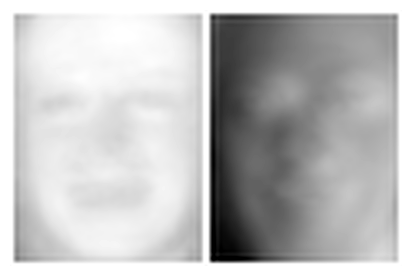

correlation: 0.996


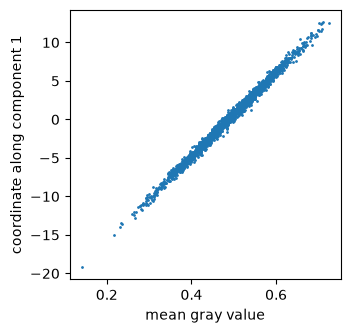

In [7]:
W_raw, lambdas_raw = pca_svd(X_raw, 1)
w_raw = W_raw[:, 0] * np.sign(W_raw[:, 0].sum())  # fix the sign
total_raw = np.sum((X_raw - X_raw.mean(axis=0)) ** 2) / N
print("share of the variance along the first component:")
print(f"  original gray values: {lambdas_raw[0] / total_raw:.0%}")
print(f"  standardized images:  {lambdas[0] / total:.0%}")
both = np.array([w_raw, W[:, 0]])
both = both / np.abs(both).max(axis=1, keepdims=True)
utils.render(both, 2, 1, vmax=1)

brightness = X_raw.mean(axis=1)
coordinate = (X_raw - X_raw.mean(axis=0)) @ w_raw
print(f"correlation: {np.corrcoef(brightness, coordinate)[0, 1]:.3f}")
utils.scatterplot(
    brightness,
    coordinate,
    "mean gray value",
    "coordinate along component 1",
    equal=False,
)

Without the standardization, all pixels of the first component have the same sign (left image), and the coordinate of a face along it is almost exactly its brightness.

**Question.** What does the standardization achieve? (One of the multiple-choice questions of the quiz asks about this.)

## Exercise 2: Reconstruction from the First Components

PCA describes a point $\boldsymbol{x}$ by its coordinates along the first $k$ components, the columns of $W$ of shape $d \times k$ (orthonormal: $W^\top W = I$),

$$
h_i = \boldsymbol{w}_i^\top (\boldsymbol{x} - \boldsymbol{\mu}), \qquad i = 1, \dots, k;
$$

these $k$ numbers replace the $d$ entries of $\boldsymbol{x}$ (compression). The reconstruction from them is

$$
\widehat{\boldsymbol{x}} = \boldsymbol{\mu} + \sum_{i=1}^k h_i\, \boldsymbol{w}_i = \boldsymbol{\mu} + W W^\top (\boldsymbol{x} - \boldsymbol{\mu}).
$$

- **Implement `reconstruct(X, mu, W)`**, which returns the reconstructions $\widehat{\boldsymbol{x}}_1, \dots, \widehat{\boldsymbol{x}}_N$ of all rows of `X` as the rows of an array of shape (N, d), for the mean `mu`, shape (d,), of the data the components were computed from and the components `W`, shape (d, k). The points need not be the data the components were computed from: use the given `mu`.


In [8]:
def reconstruct(X: np.ndarray, mu: np.ndarray, W: np.ndarray) -> np.ndarray:
    """
    Project data onto k principal components and reconstruct it.

    Args:
        X (np.ndarray): Data matrix of shape (N, d).
        mu (np.ndarray): Mean vector of shape (d,).
        W (np.ndarray): Principal components of shape (d, k).

    Returns:
        X_hat (np.ndarray): Reconstructed data matrix of shape (N, d).
    """
    # Project data points
    H = (X - mu) @ W

    # Reconstruct data points (approximation)
    X_hat = H @ W.T + mu

    return X_hat

We reconstruct six faces from 5, 20 and 100 components (rows 2 to 4, the originals in the first row), and compare the mean squared reconstruction error with the variances along the components that are left out.


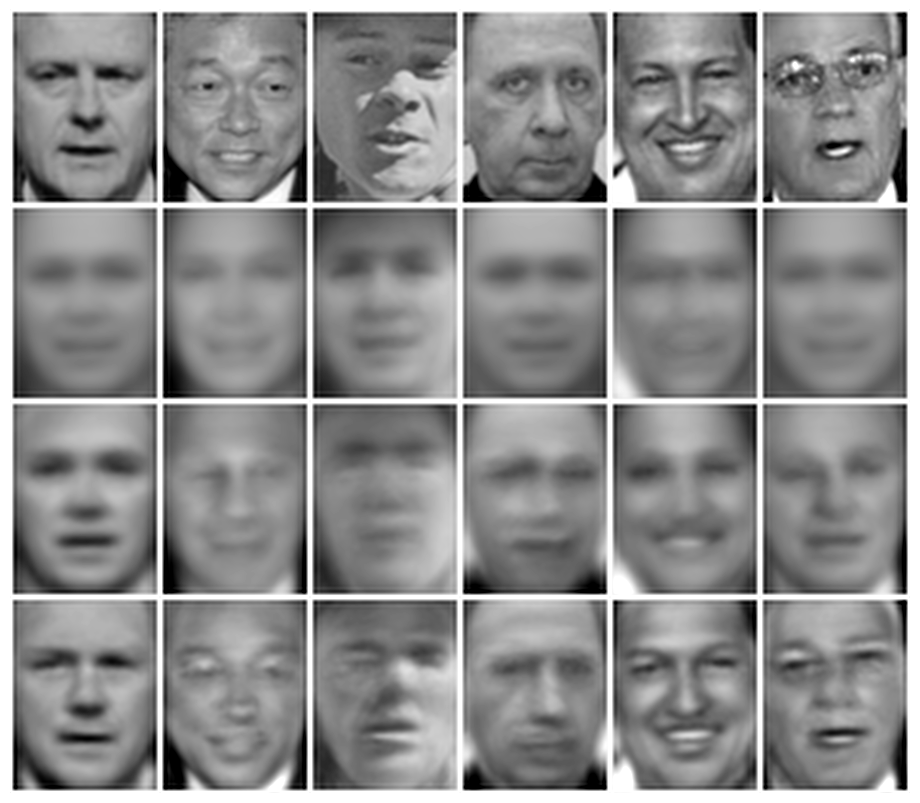

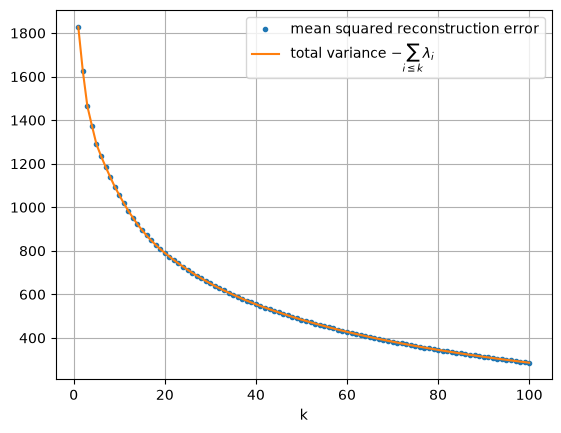

In [9]:
faces = [X[:6]]
for k in [5, 20, 100]:
    faces.append(reconstruct(X[:6], mu, W[:, :k]))
utils.render(np.concatenate(faces), 6, 4, vmax=3)

ks = np.arange(1, 101)
error = [np.mean(np.sum((X - reconstruct(X, mu, W[:, :k])) ** 2, 1)) for k in ks]
plt.plot(ks, error, ".", label="mean squared reconstruction error")
plt.plot(
    ks, total - np.cumsum(lambdas), label=r"total variance $-\sum_{i \leq k} \lambda_i$"
)
plt.xlabel("k")
plt.legend()
plt.grid(True)
plt.show()

With 100 of 2914 numbers per face, the faces are still easy to recognize; with 5, only the lighting and the rough shape remain.

**Question.** The two curves agree. What is the mean squared reconstruction error in terms of the variances $\lambda_i$, and what does this say about minimizing the noise and maximizing the signal? (One of the multiple-choice questions of the quiz asks about this.)

## Exercise 3: Power Iteration

Often only the first principal component is needed. The power iteration finds it without computing all components: starting from a vector $\boldsymbol{w}^{(0)}$, it repeats

$$
\boldsymbol{v}^{(t)} = \widehat\Sigma\, \boldsymbol{w}^{(t-1)}, \qquad \boldsymbol{w}^{(t)} = \frac{\boldsymbol{v}^{(t)}}{\|\boldsymbol{v}^{(t)}\|}, \qquad t = 1, 2, \dots
$$

and $\boldsymbol{w}^{(t)}$ converges to the first component $\boldsymbol{w}_1$ (if $\lambda_1 > \lambda_2$ and $\boldsymbol{w}^{(0)}$ is not orthogonal to $\boldsymbol{w}_1$). The objective $J(\boldsymbol{w}) = \boldsymbol{w}^\top \widehat\Sigma\, \boldsymbol{w}$, the variance of the data along $\boldsymbol{w}$, increases towards $\lambda_1$.

For data with many dimensions, $\widehat\Sigma$ does not fit into memory: images of 316 × 316 pixels have $d \approx 100\,000$, and $\widehat\Sigma$ has $d^2 = 10^{10}$ entries, 80 GB. So do not form $\widehat\Sigma$, but compute the product as

$$
\widehat\Sigma\, \boldsymbol{w} = \frac1N\, \bar X^\top (\bar X \boldsymbol{w}):
$$

first the $N$ numbers $\bar X \boldsymbol{w}$, then $\bar X^\top$ times them. This needs no more memory than $\bar X$ itself.

- **Implement `power_iteration(X, w0, n_iter)`**, which returns the pair `(w, J)`: the unit vector $\boldsymbol{w}^{(T)}$ after $T$ = `n_iter` steps from the start vector `w0` (shape (d,), not necessarily of unit length), an array of shape (d,), and the objective $J(\boldsymbol{w}^{(t)})$ after every step $t = 1, \dots, T$, an array of shape (n_iter,).


In [10]:
def power_iteration(X, w0, n_iter):
    """
    Approximate the first principal component using power iteration.

    Args:
        - X (np.ndarray): Data matrix of shape (N, d).
        - w0 (np.ndarray): Non-zero starting vector of shape (d,)
        - n_iter (int): Number of iteration steps.

    Returns:
        - w (np.ndarray): Estimated first principal component of shape (d,).
        - J (np.ndarray): Variance along w after each step, shape (n_iter,).
    """
    # Center data
    mu = np.mean(X, axis=0)
    X_centered = X - mu

    # Normalize starting vector
    norm = np.linalg.norm(w0)
    if norm == 0:
        raise ValueError("w0 must be nonzero.")
    w = w0 / norm

    # Store objective after each step
    J = np.zeros(n_iter)

    for t in range(n_iter):
        # Multiply by covariance matrix without forming it
        v = X_centered.T @ (X_centered @ w) / N

        # Normalize updated vector
        norm = np.linalg.norm(v)
        if norm == 0:
            raise ValueError("The iteration reached a zero vector.")
        w = v / norm

        # Compute variance along the updated direction
        projections = X_centered @ w
        J[t] = projections @ projections / N

    return w, J

We run 50 steps from a random start vector and follow the objective and the angle to the first component from Exercise 1.


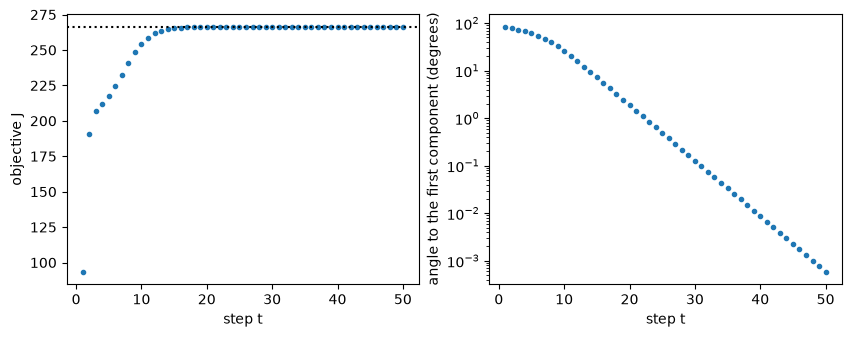

In [11]:
w0 = np.random.default_rng(0).normal(size=d)
w, J = power_iteration(X, w0, 50)

angles = []
for t in range(1, 51):
    w_t, _ = power_iteration(X, w0, t)
    angles.append(np.degrees(np.arccos(min(1, abs(w_t @ W[:, 0])))))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].plot(range(1, 51), J, ".")
axes[0].axhline(lambdas[0], color="k", ls=":")
axes[0].set_xlabel("step t")
axes[0].set_ylabel("objective J")
axes[1].semilogy(range(1, 51), angles, ".")
axes[1].set_xlabel("step t")
axes[1].set_ylabel("angle to the first component (degrees)")
plt.show()

The objective reaches $\lambda_1$ (dotted) after about 15 steps, and the angle shrinks by about the same factor in every step, a straight line on the logarithmic scale.

**Question.** What determines this factor, and when does the iteration converge slowly or not at all? (One of the multiple-choice questions of the quiz asks about this.)

### Many Pixels

For the faces above, $\widehat\Sigma$ would still fit into memory. For larger images it does not. We enlarge the first 200 faces five times in each direction, every pixel becomes a block of 5 × 5 pixels, and run the power iteration on them: your function only needs the data.


d = 72850
the data needs 117 MB
the covariance needs 42 GB


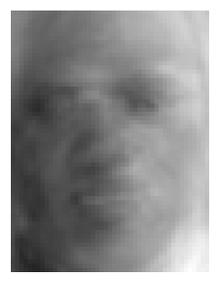

In [12]:
X_large = np.kron(images[:200], np.ones((5, 5))).reshape(200, -1)
d_large = X_large.shape[1]
print(f"d = {d_large}")
print(f"the data needs {X_large.nbytes / 1e6:.0f} MB")
print(f"the covariance needs {d_large ** 2 * 8 / 1e9:.0f} GB")

w0_large = np.random.default_rng(0).normal(size=d_large)
w_large, J_large = power_iteration(X_large, w0_large, 30)
utils.render(w_large, 1, 1, shape=(310, 235), width=200)

Like the first eigenfaces above, the first component of these 200 faces shows the lighting and the rough shape of a face. Computing it took a little more memory than the data itself, while forming $\widehat\Sigma$ would have needed tens of gigabytes. The quiz also checks your function on images of 100 000 pixels.
